# CRISP-DM phase 2 : Data Understanding, D1 (Heart Disease Dataset (Comprehensive))

Responsable : Aziz (maladies cardiaques)

**À surveiller :** Fusion de 5 bases (Cleveland, Hongrie, Suisse, Long Beach, Statlog). Attendu : beaucoup de doublons (même patient présent dans plusieurs bases) et des `cholesterol = 0` (valeur manquante codée 0).

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parents[1]))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.datasets import load, REGISTRY

DS = 'D1'
df, target = load(DS)   # vérifie aussi la taille face au tableau 2 de l'article
REGISTRY[DS]['name'], df.shape

[D1] lignes=1190 pos=629 neg=561 | article: lignes=1190 pos=629 neg=561 -> OK


('Heart Disease Dataset (Comprehensive)', (1190, 12))

## 1. Structure et dictionnaire des variables
Compléter le tableau dans le rapport : nom, signification médicale, type (numérique, binaire, catégorielle), unité.

In [2]:
df.head()

,age,sex,chest pain type,resting bp s,cholesterol,fasting blood sugar,resting ecg,max heart rate,exercise angina,oldpeak,ST slope,target
0,40,1,2,140,289,0,0,172,0,0.0,1,0
1,49,0,3,160,180,0,0,156,0,1.0,2,1
2,37,1,2,130,283,0,1,98,0,0.0,1,0
3,48,0,4,138,214,0,0,108,1,1.5,2,1
4,54,1,3,150,195,0,0,122,0,0.0,1,0


In [3]:
pd.DataFrame({'dtype': df.dtypes, 'n_unique': df.nunique(), 'min': df.min(numeric_only=True), 'max': df.max(numeric_only=True)})

,dtype,n_unique,min,max
age,int64,50,28.0,77.0
sex,int64,2,0.0,1.0
chest pain type,int64,4,1.0,4.0
resting bp s,int64,67,0.0,200.0
cholesterol,int64,222,0.0,603.0
fasting blood sugar,int64,2,0.0,1.0
resting ecg,int64,3,0.0,2.0
max heart rate,int64,119,60.0,202.0
exercise angina,int64,2,0.0,1.0
oldpeak,float64,53,-2.6,6.2


## 2. Variable cible

target
0    561
1    629
Name: count, dtype: int64 
 target
0    0.471
1    0.529
Name: count, dtype: float64


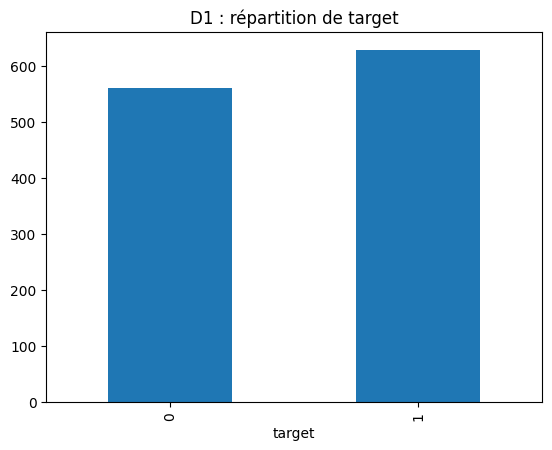

In [4]:
counts = df[target].value_counts().sort_index()
print(counts, '\n', (counts / len(df)).round(3))
counts.plot.bar(title=f'{DS} : répartition de {target}'); plt.show()

## 3. Valeurs manquantes (vraies et codées)

In [5]:
print(df.isna().sum()[df.isna().sum() > 0])
# zéros médicalement impossibles
for c in ['cholesterol', 'chol', 'resting bp s', 'trestbps', 'serum_sodium', 'platelets']:
    if c in df: print(c, '= 0 :', (df[c] == 0).sum())
for c, code in [('ca', 4), ('thal', 0)]:
    if c in df: print(c, '=', code, ':', (df[c] == code).sum())

Series([], dtype: int64)
cholesterol = 0 : 172
resting bp s = 0 : 1


## 4. Doublons
L'article ne dit pas les avoir supprimés : on les **garde** pour reproduire ses résultats, puis on relance avec `--dedup` pour mesurer leur effet.

In [6]:
n_dup = df.duplicated().sum()
print(f'{n_dup} doublons sur {len(df)} lignes -> {len(df) - n_dup} lignes uniques')
df.drop_duplicates()[target].value_counts()

272 doublons sur 1190 lignes -> 918 lignes uniques


target
1    508
0    410
Name: count, dtype: int64

## 5. Statistiques descriptives et distributions

In [7]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,1190.0,53.72,9.36,28.0,47.0,54.0,60.00,77.0
sex,1190.0,0.76,0.42,0.0,1.0,1.0,1.00,1.0
chest pain type,1190.0,3.23,0.94,1.0,3.0,4.0,4.00,4.0
resting bp s,1190.0,132.15,18.37,0.0,120.0,130.0,140.00,200.0
cholesterol,1190.0,210.36,101.42,0.0,188.0,229.0,269.75,603.0
fasting blood sugar,1190.0,0.21,0.41,0.0,0.0,0.0,0.00,1.0
resting ecg,1190.0,0.70,0.87,0.0,0.0,0.0,2.00,2.0
max heart rate,1190.0,139.73,25.52,60.0,121.0,140.5,160.00,202.0
exercise angina,1190.0,0.39,0.49,0.0,0.0,0.0,1.00,1.0
oldpeak,1190.0,0.92,1.09,-2.6,0.0,0.6,1.60,6.2


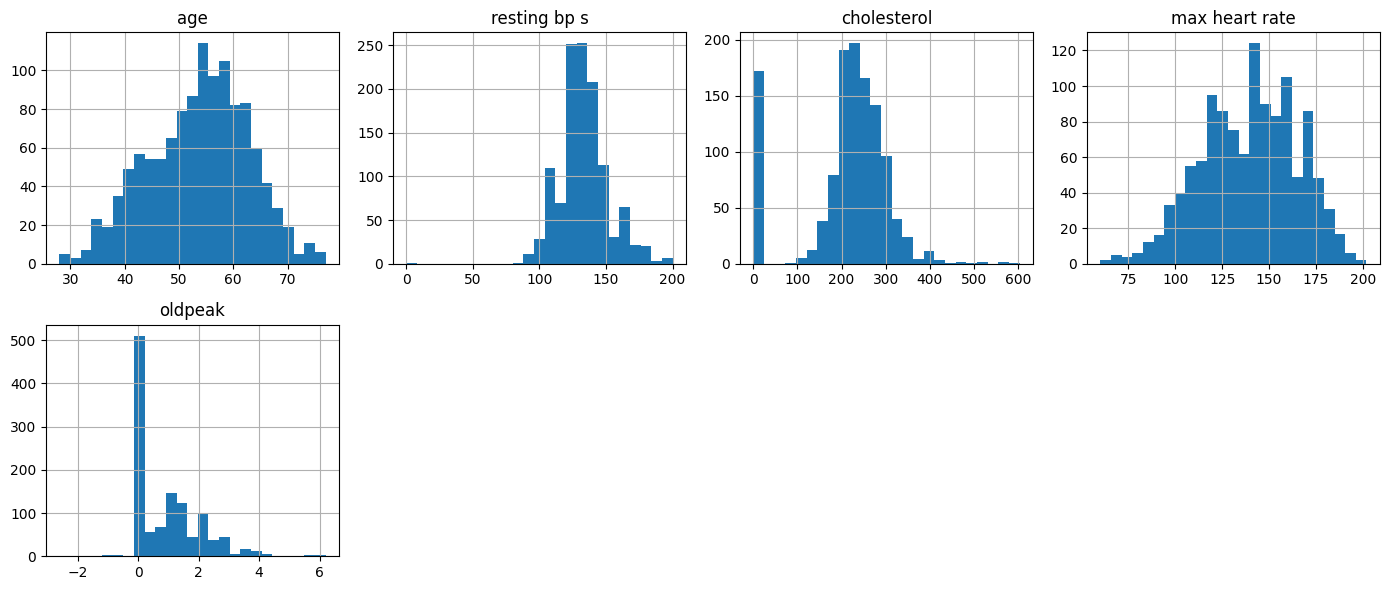

In [8]:
num = [c for c in df.columns if c != target and df[c].nunique() > 5]
df[num].hist(bins=25, figsize=(14, 3 * ((len(num) + 3) // 4)), layout=(-1, 4)); plt.tight_layout(); plt.show()

## 6. Valeurs aberrantes (méthode IQR)
Interpréter médicalement : erreur de saisie ou patient réellement extrême ?

In [9]:
q1, q3 = df[num].quantile(0.25), df[num].quantile(0.75)
iqr = q3 - q1
((df[num] < q1 - 1.5 * iqr) | (df[num] > q3 + 1.5 * iqr)).sum().sort_values(ascending=False)

cholesterol       193
resting bp s       37
oldpeak            11
max heart rate      1
age                 0
dtype: int64

## 7. Variables selon la classe

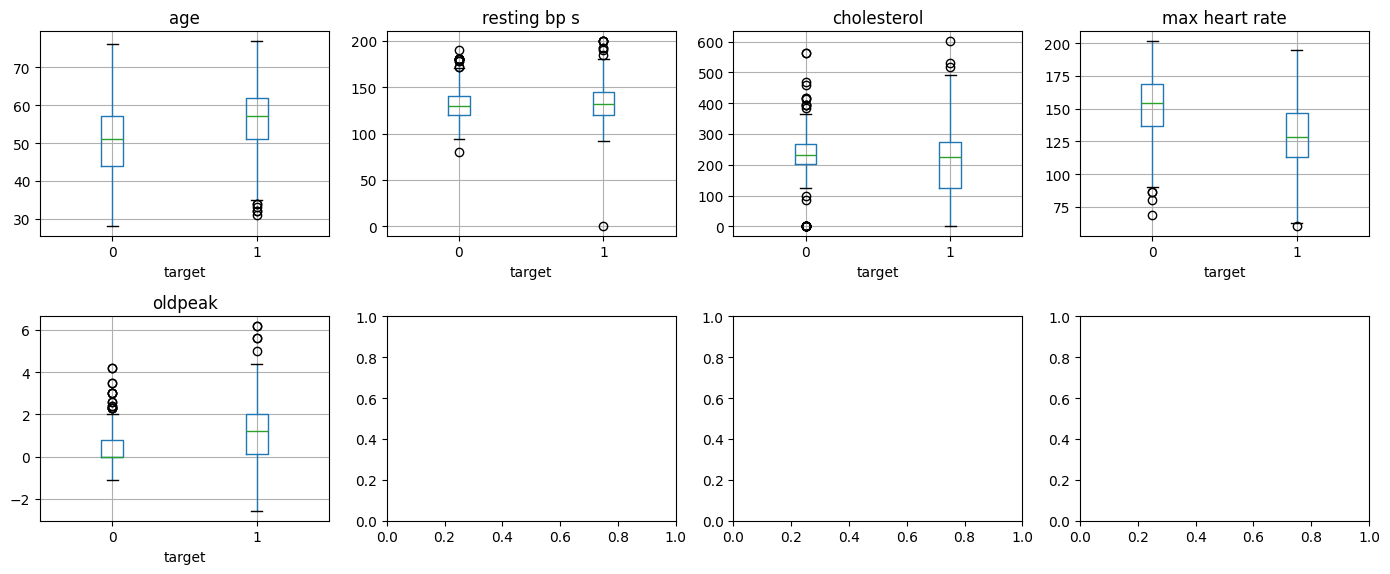

In [10]:
fig, axes = plt.subplots((len(num) + 3) // 4, 4, figsize=(14, 3 * ((len(num) + 3) // 4)))
for ax, c in zip(axes.flat, num):
    df.boxplot(column=c, by=target, ax=ax)
plt.suptitle(''); plt.tight_layout(); plt.show()

In [11]:
cat = [c for c in df.columns if c != target and df[c].nunique() <= 5]
for c in cat:
    print(pd.crosstab(df[c], df[target], normalize='index').round(2), '\n')

target     0     1
sex               
0       0.75  0.25
1       0.39  0.61 

target              0     1
chest pain type            
1                0.62  0.38
2                0.86  0.14
3                0.68  0.32
4                0.23  0.77 

target                  0     1
fasting blood sugar            
0                    0.53  0.47
1                    0.26  0.74 

target          0     1
resting ecg            
0            0.52  0.48
1            0.34  0.66
2            0.45  0.55 

target              0     1
exercise angina            
0                0.66  0.34
1                0.17  0.83 



target       0     1
ST slope            
0         0.00  1.00
1         0.79  0.21
2         0.21  0.79
3         0.27  0.73 



## 8. Corrélations

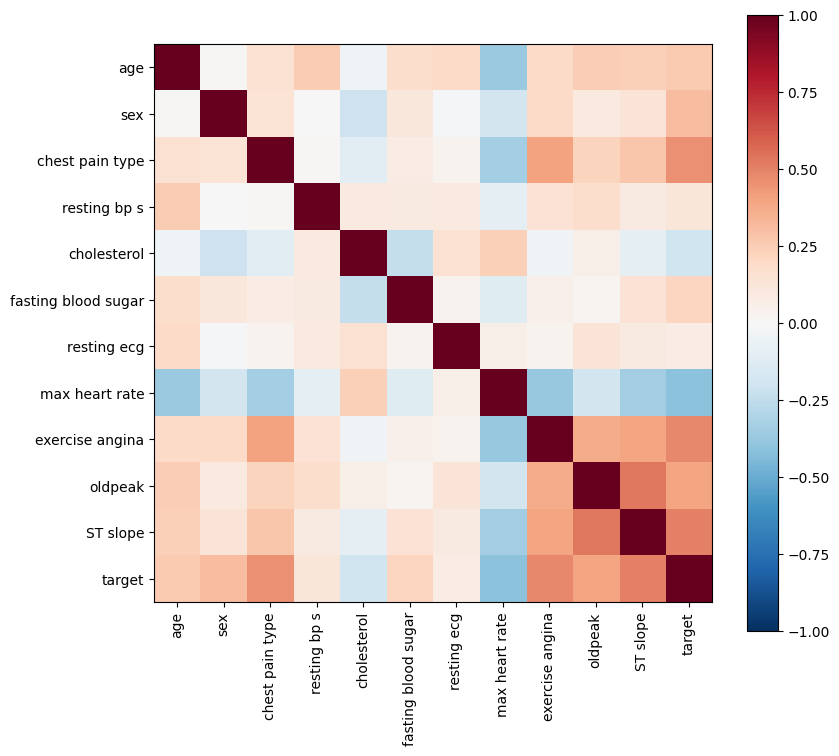

ST slope               0.505608
exercise angina        0.481467
chest pain type        0.460127
max heart rate        -0.413278
oldpeak                0.398385
sex                    0.311267
age                    0.262029
fasting blood sugar    0.216695
cholesterol           -0.198366
resting bp s           0.121415
resting ecg            0.073059
Name: target, dtype: float64

In [12]:
corr = df.select_dtypes('number').corr()
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90); ax.set_yticks(range(len(corr)), corr.columns)
plt.colorbar(im); plt.show()
corr[target].drop(target).sort_values(key=abs, ascending=False)

## 9. Conclusions pour la préparation (phase 3)

- Variables à encoder :
- Valeurs manquantes / codées à traiter :
- Doublons : gardés (reproduction) + expérience `--dedup`
- Normalisation : StandardScaler dans le Pipeline (ajusté sur le train)
- Points pour la discussion critique :